# A atenção do Transformer treinado

O bigrama e o trigrama só enxergam 1 ou 2 tokens para trás: a nota pedida sai da visão deles logo na
primeira palavra. O Transformer (`src/nano_review/models/transformer.py`) tem a **atenção**: em cada
posição, cada cabeça distribui um peso entre **todas** as posições anteriores, e a saída é a média
ponderada do que elas carregam.

Este notebook abre o checkpoint final da Etapa 3 (`models/transformer.pt`, gerado pelo `dvc repro`) e
responde a três perguntas:

1. Como são os mapas de atenção numa resenha?
2. Alguma cabeça olha para o token `<nota_k>` mesmo longe do começo?
3. Trocar a nota muda a previsão várias palavras depois? Isso é o que o trigrama não consegue.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from matplotlib.colors import LinearSegmentedColormap
from tokenizers import Tokenizer

from nano_review.data.dataset import ReviewDataset, make_loader
from nano_review.models.transformer import (
    CausalSelfAttention,
    TransformerConfig,
    TransformerLanguageModel,
    count_parameters,
)
from nano_review.tokenization.bpe import encode_review

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Mesmo padrão visual da EDA; mapa de calor com a rampa azul (claro = pouco, escuro = muito).
BLUE_RAMP = ["#f4f8fe", "#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]
CMAP = LinearSegmentedColormap.from_list("blue_ramp", BLUE_RAMP)
plt.rcParams.update(
    {
        "figure.facecolor": "#fcfcfb",
        "axes.facecolor": "#fcfcfb",
        "axes.edgecolor": "#c3c2b7",
        "axes.labelcolor": "#52514e",
        "axes.titlecolor": "#0b0b0b",
        "axes.titlesize": 10,
        "axes.titleweight": "bold",
        "xtick.color": "#52514e",
        "ytick.color": "#52514e",
        "font.size": 9,
        "figure.dpi": 100,
        "savefig.dpi": 150,
        "savefig.bbox": "tight",
    }
)

tokenizer = Tokenizer.from_file(str(ROOT / "models" / "tokenizer.json"))
checkpoint = torch.load(ROOT / "models" / "transformer.pt", weights_only=True)
config = TransformerConfig(**checkpoint["config"])
model = TransformerLanguageModel(config)
model.load_state_dict(checkpoint["state_dict"])
model.eval()
print(config)
print(
    "parâmetros:",
    f"{count_parameters(model):,}".replace(",", "."),
    "| melhor passo:",
    checkpoint["step"],
)


def attention_maps(tokens: torch.Tensor) -> torch.Tensor:
    """Roda o forward e junta os pesos de atenção de todas as camadas: (camadas, B, H, T, T)."""
    with torch.no_grad():
        model(tokens)
    maps = []
    for block in model.blocks:
        attention = block.attention
        assert isinstance(attention, CausalSelfAttention) and attention.last_attention is not None
        maps.append(attention.last_attention)
    return torch.stack(maps)

TransformerConfig(vocab_size=8000, block_size=128, d_model=256, n_layers=4, n_heads=4, dropout=0.0)
parâmetros: 5.240.320 | melhor passo: 15000


## 1. Mapas de atenção numa resenha

Cada quadrado é uma cabeça. A linha `i` mostra como a posição `i` distribui a atenção entre as
posições `0..i`. Acima da diagonal fica o futuro, sempre vazio, por causa da máscara causal. A
resenha é inventada.

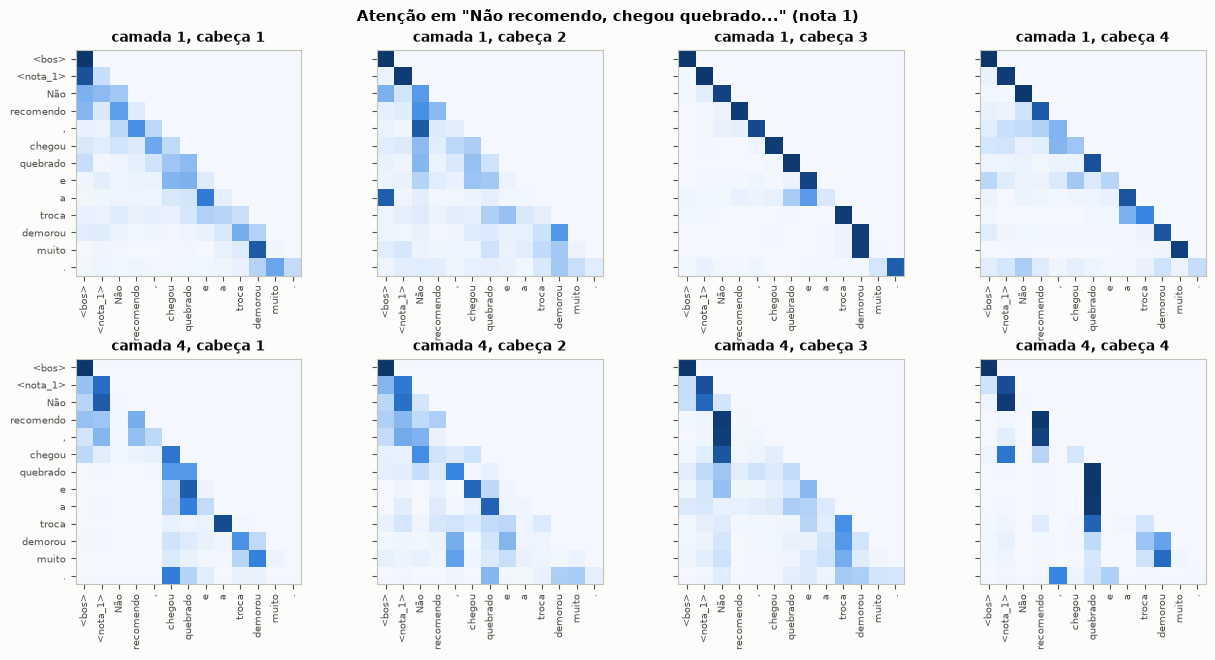

In [2]:
ids = encode_review(tokenizer, "Não recomendo, chegou quebrado e a troca demorou muito.", rating=1)
tokens = torch.tensor([ids[:-1]])  # a entrada do modelo, como no treino (sem o <eos>)
labels = [tokenizer.id_to_token(i).replace("▁", "") for i in ids[:-1]]
maps = attention_maps(tokens)[:, 0]  # (camadas, H, T, T)

layers_to_show = [0, config.n_layers - 1]
fig, axes = plt.subplots(len(layers_to_show), config.n_heads, figsize=(3.2 * config.n_heads, 6.6))
for row, layer in enumerate(layers_to_show):
    for head in range(config.n_heads):
        ax = axes[row, head]
        ax.imshow(maps[layer, head].numpy(), cmap=CMAP, vmin=0, vmax=1)
        ax.set_title(f"camada {layer + 1}, cabeça {head + 1}")
        ax.set_xticks(range(len(labels)), labels=labels, rotation=90, fontsize=7)
        ax.set_yticks(range(len(labels)), labels=labels if head == 0 else [], fontsize=7)
fig.suptitle('Atenção em "Não recomendo, chegou quebrado..." (nota 1)', fontweight="bold")
fig.tight_layout()
fig.savefig(FIG_DIR / "attention_maps.png")
plt.show()

## 2. Alguma cabeça olha para a nota?

Uma resenha não basta para concluir nada. A conta abaixo usa 1.000 resenhas da validação. Para cada
cabeça, ela mede o peso médio que as posições **a partir do 4º token de texto** dão ao token
`<nota_k>` (posição 1). Essas posições estão fora da janela do trigrama.

A referência é a atenção **uniforme**: uma cabeça que espalhasse o peso igualmente entre tudo o que
vê daria à nota, em média, o valor da linha "uniforme". Bem acima disso, a cabeça está procurando a
nota de propósito.

In [3]:
validation = pd.read_parquet(ROOT / "data" / "curated" / "validation.parquet").sample(
    1_000, random_state=0
)
loader = make_loader(
    ReviewDataset(validation, tokenizer, config.block_size), tokenizer, 64, False, 0
)
FIRST_POSITION = 5  # posição 5 = 4º token de texto (<bos>, <nota_k> e 3 tokens ficam de fora)
total = torch.zeros(config.n_layers, config.n_heads)
uniform_total, count = 0.0, 0
for x, y in loader:
    maps = attention_maps(x)  # (camadas, B, H, T, T)
    valid = (y != -100)[:, FIRST_POSITION:]  # só posições de texto, sem padding
    to_rating = maps[:, :, :, FIRST_POSITION:, 1]  # peso dado à posição 1 (a nota)
    total += (to_rating * valid[None, :, None, :]).sum(dim=(1, 3))
    positions = torch.arange(FIRST_POSITION, x.size(1)).float()
    uniform_total += float(((1 / (positions + 1))[None, :] * valid).sum())
    count += int(valid.sum())

to_rating = (total / count).numpy()
uniform = uniform_total / count
table = pd.DataFrame(
    to_rating.round(3),
    index=[f"camada {i + 1}" for i in range(config.n_layers)],
    columns=[f"cabeça {h + 1}" for h in range(config.n_heads)],
)
print(f"uniforme (referência): {uniform:.3f}")
table

uniforme (referência): 0.059


,cabeça 1,cabeça 2,cabeça 3,cabeça 4
camada 1,0.021,0.034,0.008,0.024
camada 2,0.055,0.117,0.083,0.148
camada 3,0.040,0.047,0.279,0.142
camada 4,0.031,0.040,0.048,0.058


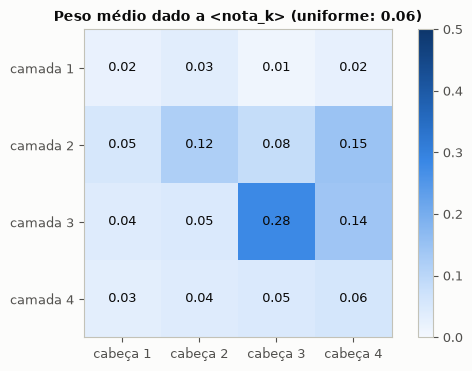

In [4]:
fig, ax = plt.subplots(figsize=(1.3 * config.n_heads + 1.5, 0.7 * config.n_layers + 1.2))
image = ax.imshow(to_rating, cmap=CMAP, vmin=0, vmax=max(0.5, float(to_rating.max())))
for (layer, head), value in np.ndenumerate(to_rating):
    ax.text(
        head,
        layer,
        f"{value:.2f}",
        ha="center",
        va="center",
        fontsize=9,
        color="#ffffff" if value > 0.6 * max(0.5, float(to_rating.max())) else "#0b0b0b",
    )
ax.set_xticks(range(config.n_heads), labels=[f"cabeça {h + 1}" for h in range(config.n_heads)])
ax.set_yticks(range(config.n_layers), labels=[f"camada {i + 1}" for i in range(config.n_layers)])
ax.set_title(f"Peso médio dado a <nota_k> (uniforme: {uniform:.2f})")
fig.colorbar(image, ax=ax, fraction=0.046)
fig.savefig(FIG_DIR / "attention_to_rating.png")
plt.show()

## 3. Trocar a nota muda a previsão lá na frente?

O mesmo começo de resenha, quatro palavras de texto depois da nota, com `<nota_1>` e com `<nota_5>`.
Para o trigrama, as duas versões seriam **idênticas**: a nota já saiu da janela de duas palavras.
Se o Transformer prevê palavras diferentes, ele está usando a nota pela atenção.

In [5]:
def next_token_table(text: str, top: int = 8) -> pd.DataFrame:
    columns = {}
    for rating in (1, 5):
        ids = encode_review(tokenizer, text, rating=rating)[:-1]  # sem o <eos>: a frase continua
        with torch.no_grad():
            probabilities = torch.softmax(model(torch.tensor([ids]))[0, -1], dim=-1)
        best = probabilities.topk(top)
        columns[f"<nota_{rating}>"] = [
            f"{tokenizer.id_to_token(int(i))} ({p:.0%})"
            for p, i in zip(best.values, best.indices, strict=True)
        ]
    return pd.DataFrame(columns)


print('Começo: "O produto chegou e" -> próximo token')
next_token_table("O produto chegou e")

Começo: "O produto chegou e" -> próximo token


,<nota_1>,<nota_5>
0,▁não (11%),▁é (14%)
1,▁eu (6%),▁está (7%)
2,▁a (4%),▁antes (7%)
3,▁depois (4%),▁no (4%)
4,▁o (3%),▁eu (3%)
5,▁está (3%),▁muito (3%)
6,▁no (2%),▁foi (3%)
7,▁é (2%),▁gostei (3%)


In [6]:
print('Começo: "Comprei para minha mãe e ela" -> próximo token')
next_token_table("Comprei para minha mãe e ela")

Começo: "Comprei para minha mãe e ela" -> próximo token


,<nota_1>,<nota_5>
0,▁está (16%),▁adorou (28%)
1,▁não (14%),▁gostou (21%)
2,▁simplesmente (6%),▁amou (19%)
3,▁gostou (6%),▁está (9%)
4,▁ficou (6%),▁ficou (3%)
5,▁adorou (3%),▁achou (2%)
6,▁disse (3%),▁esta (1%)
7,▁já (2%),▁tá (1%)


## O que os três resultados dizem juntos

**Mapas (seção 1).** As cabeças se dividem em funções diferentes, e nenhuma foi programada para isso. O
treino descobriu esses padrões porque eles ajudam a prever o próximo token:

- **O próprio token:** na camada 1, a cabeça 3 é quase só a diagonal principal. Cada posição olha
  para si mesma.
- **O token anterior:** na camada 1, a cabeça 1 forma a diagonal logo abaixo da principal. É o que o
  bigrama faz, agora como uma peça entre várias.
- **Palavras-chave da resenha:** na camada 4, a cabeça 3 faz "recomendo", "," e "chegou" voltarem ao
  "Não". Na cabeça 4, "e", "a" e "troca" voltam a "quebrado". São as palavras que decidem o tom.
- **A nota:** nas cabeças 1 a 3 da camada 4, "Não" e "recomendo" dão peso a `<nota_1>`.

**Peso direto na nota (seção 2).** A cabeça mais atenta à nota (camada 3, cabeça 3) dá a ela **0,28**
do peso, quase 5 vezes a atenção uniforme (0,06). As cabeças 2 e 4 da camada 2 e a cabeça 4 da camada
3 ficam entre 0,12 e 0,15. No modelo da Etapa 2, o máximo era 0,11.

O modelo final consulta a nota mais diretamente, e ele também tem a coerência maior (0,617 → 0,721,
`docs/experiments.md`). Os dois fatos combinam, mas isto sozinho é correlação. A prova de que a
coerência vem da nota é o experimento E6: retreinado sem `<nota_k>`, o modelo cai para 0,312, o acaso.

Mesmo assim, medir só a atenção direta subestima o uso da nota. Nas primeiras camadas, a informação
dela é copiada para os primeiros tokens ("Não", "recomendo"), e a conexão residual a leva adiante.

**A prova direta (seção 3).** Com o mesmo começo de resenha, trocar `<nota_1>` por `<nota_5>` muda a
previsão **seis tokens depois** da nota. "Comprei para minha mãe e ela" continua assim:

- na nota 5, com "adorou", "gostou" e "amou", que somam 68% da probabilidade;
- na nota 1, com "está" e "não" no topo, e "adorou" com só 3%.

Para o trigrama, as duas previsões seriam idênticas, porque a nota já saiu da janela de duas palavras.
É a limitação que o charter apontou no baseline.